In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
from torch import nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

import torchvision.transforms as transforms
from torchvision import models

from PIL import Image

from tqdm.auto import tqdm

from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import f1_score
from sklearn.metrics import confusion_matrix

In [2]:
device = "cuda" if torch.cuda.is_available() else "cpu"

In [3]:
class BoxInfo:
    def __init__(self, line):
        words = line.split()
        self.category = words.pop()
        words = [int(string) for string in words]
        self.player_ID = words[0]
        del words[0]

        x1, y1, x2, y2, frame_ID, lost, grouping, generated = words
        self.box = x1, y1, x2, y2
        self.frame_ID = frame_ID
        self.lost = lost
        self.grouping = grouping
        self.generated = generated

In [4]:
dataset_root = "/kaggle/input/datasets/ahmedmohamed365/volleyball"

def load_tracking_annot(path):
    with open(path, 'r') as file:
        player_boxes = {idx:[] for idx in range(12)}
        frame_boxes_dct = {}

        for idx, line in enumerate(file):
            box_info = BoxInfo(line)
            if box_info.player_ID > 11:
                continue
            player_boxes[box_info.player_ID].append(box_info)

        # let's create view from frame to boxes
        for player_ID, boxes_info in player_boxes.items():
            # let's keep the middle 9 frames only (enough for this task empirically)
            boxes_info = boxes_info[5:]
            boxes_info = boxes_info[:-6]

            for box_info in boxes_info:
                if box_info.frame_ID not in frame_boxes_dct:
                    frame_boxes_dct[box_info.frame_ID] = []

                frame_boxes_dct[box_info.frame_ID].append(box_info)

        return frame_boxes_dct

In [5]:
root = "/kaggle/input/datasets/ahmedmohamed365/volleyball/volleyball_/videos"

data = []

for video_folder_name in os.listdir(root):
    current_video_folder_path = os.path.join(root, video_folder_name)

    if not os.path.isdir(current_video_folder_path):
        continue

    annotations_path = os.path.join(current_video_folder_path, "annotations.txt")

    if not os.path.isfile(annotations_path):
        continue

    video_id = int(video_folder_name)

    with open(annotations_path, "r") as f:
        for line in f:
            parts = line.strip().split()

            if len(parts) < 2:
                continue

            image_filename = parts[0]                 # 13456.jpg
            group_label = parts[1]                    # r_spike

            clip_id = os.path.splitext(image_filename)[0]   # 13456

            image_path = os.path.join(
                current_video_folder_path,
                clip_id,
                image_filename
            )

            tracking_path = os.path.join(
                "/kaggle/input/datasets/ahmedmohamed365/volleyball/volleyball_tracking_annotation/volleyball_tracking_annotation",
                str(video_id),
                clip_id,
                f"{clip_id}.txt"
            )

            data.append({
                "video_id": video_id,
                "clip_id": clip_id,
                "image_path": image_path,
                "tracking_path": tracking_path,
                "group_label": group_label
            })

In [6]:
train_videos = [1, 3, 6, 7, 10, 13, 15, 16, 18, 22, 23, 31, 32, 36, 38, 39, 40, 41, 42, 48, 50, 52, 53, 54]
val_videos = [0, 2, 8, 12, 17, 19, 24, 26, 27, 28, 30, 33, 46, 49, 51]
test_videos = [4, 5, 9, 11, 14, 20, 21, 25, 29, 34, 35, 37, 43, 44, 45, 47]

train_data = []
val_data = []
test_data = []

for sample in data:
    if sample["video_id"] in train_videos:
        train_data.append(sample)

    elif sample["video_id"] in val_videos:
        val_data.append(sample)

    else:
        test_data.append(sample)

In [7]:
label_map = {
    "l_pass": 0,
    "r_pass": 1,
    "l_spike": 2,
    "r_spike": 3,
    "l_set": 4,
    "r_set": 5,
    "l_winpoint": 6,
    "r_winpoint": 7,

    "l-pass": 0,
    "r-pass": 1,
    "l-spike": 2,
    "r-spike": 3,
    "l-set": 4,
    "r-set": 5,
    "l-winpoint": 6,
    "r-winpoint": 7
}

In [8]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [9]:
class VolleyballDataset(Dataset):
    def __init__(self, data, transform=None):
        self.data = data
        self.transform = transform

    def __len__(self):
        return len(self.data)
        
    def __getitem__(self, idx):
    
        sample = self.data[idx]
    
        image = Image.open(sample["image_path"]).convert("RGB")
    
        frame_boxes = load_tracking_annot(sample["tracking_path"])
    
        frame_id = list(frame_boxes.keys())[0]
    
        player_crops = []
    
        for box_info in frame_boxes[frame_id][:12]:
            x1, y1, x2, y2 = box_info.box
    
            crop = image.crop((x1, y1, x2, y2))
    
            if self.transform:
                crop = self.transform(crop)
    
            player_crops.append(crop)
    
        while len(player_crops) < 12:
            player_crops.append(torch.zeros(3, 224, 224))
    
        player_crops = torch.stack(player_crops)
    
        label = torch.tensor(
            label_map[sample["group_label"]],
            dtype=torch.long
        )
    
        return player_crops, label

In [10]:
dataset = VolleyballDataset(train_data, transform)

In [11]:
LR = 1e-3
BATCH_SIZE = 16
EPOCHS = 40

In [12]:
train_dataset = VolleyballDataset(train_data, transform)
val_dataset = VolleyballDataset(val_data, transform)
test_dataset = VolleyballDataset(test_data, transform)


train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    pin_memory=True
)

In [13]:
class B3Model(nn.Module):
    def __init__(self):
        super().__init__()

        resnet = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)

        self.backbone = nn.Sequential(*list(resnet.children())[:-1])

        self.classifier = nn.Linear(2048, 8)

    def forward(self, x):
        # x: [B,12,3,224,224]
        
        B, P, C, H, W = x.shape
        x = x.view(B*P, C, H, W)
        features = self.backbone(x)
        features = features.view(B, P, 2048)
        features = features.mean(dim=1)
        out = self.classifier(features)

        return out

In [14]:
model = B3Model()

if torch.cuda.device_count() > 1:
    model = nn.DataParallel(model)

model = model.to(device)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 165MB/s] 


In [15]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=LR)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS,
    eta_min=1e-6 
)

In [16]:
total_loss_train_plot = []
total_loss_validation_plot = []
total_acc_train_plot = []
total_acc_validation_plot = []


for epoch in range(EPOCHS):
    total_acc_train = total_loss_train = total_loss_val = total_acc_val = 0
    seen_train = seen_val = 0

    model.train()
    train_bar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [train]", leave=False)
    for inputs, labels in train_bar:
        inputs = inputs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()
        outputs = model(inputs)
        train_loss = criterion(outputs, labels)
        total_loss_train += train_loss.item()
        train_loss.backward()
        optimizer.step()

        batch_correct = (torch.argmax(outputs, 1) == labels).sum().item()
        total_acc_train += batch_correct
        seen_train += labels.size(0)

        train_bar.set_postfix(
            loss=f"{train_loss.item():.4f}",
            acc=f"{total_acc_train / seen_train * 100:.2f}%",
        )
        
    true_labels = []
    predicted_labels = []
    model.eval()
    val_bar = tqdm(val_loader, desc=f"Epoch {epoch+1}/{EPOCHS} [val]", leave=False)
    with torch.no_grad():
        for inputs, labels in val_bar:
            inputs = inputs.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(inputs)

            predictions = torch.argmax(outputs, dim=1)
            true_labels.extend(labels.cpu().numpy())
            predicted_labels.extend(predictions.cpu().numpy())

            val_loss = criterion(outputs, labels)
            total_loss_val += val_loss.item()

            batch_correct = (torch.argmax(outputs, 1) == labels).sum().item()
            total_acc_val += batch_correct
            seen_val += labels.size(0)

            val_bar.set_postfix(
                loss=f"{val_loss.item():.4f}",
                acc=f"{total_acc_val / seen_val * 100:.2f}%",
            )

    avg_train_loss = total_loss_train / len(train_loader)
    avg_val_loss = total_loss_val / len(val_loader)
    scheduler.step()

    total_loss_train_plot.append(round(avg_train_loss, 4))
    total_loss_validation_plot.append(round(avg_val_loss, 4))
    total_acc_train_plot.append(round(total_acc_train / seen_train * 100, 4))
    total_acc_validation_plot.append(round(total_acc_val / seen_val * 100, 4))
    val_f1 = f1_score(
        true_labels,
        predicted_labels,
        average="macro"
    )
    print(
        f"Epoch {epoch + 1}/{EPOCHS}, "
        f"Train Loss: {avg_train_loss:.4f} "
        f"Train Accuracy: {total_acc_train / seen_train * 100:.2f}% "
        f"Validation Loss: {avg_val_loss:.4f} "
        f"Validation Accuracy: {total_acc_val / seen_val * 100:.2f}%"
        f"Validation F1: {val_f1:.4f}"
    )
    print("=" * 25)

Epoch 1/40 [train]:   0%|          | 0/135 [00:00<?, ?it/s]

Epoch 1/40 [val]:   0%|          | 0/84 [00:00<?, ?it/s]

Epoch 1/40, Train Loss: 1.6950 Train Accuracy: 34.01% Validation Loss: 1.9525 Validation Accuracy: 41.76%Validation F1: 0.3919


Epoch 2/40 [train]:   0%|          | 0/135 [00:00<?, ?it/s]

Epoch 2/40 [val]:   0%|          | 0/84 [00:00<?, ?it/s]

...

Epoch 39/40 [val]:   0%|          | 0/84 [00:00<?, ?it/s]

Epoch 39/40, Train Loss: 0.0013 Train Accuracy: 100.00% Validation Loss: 1.4049 Validation Accuracy: 70.77%Validation F1: 0.6943


Epoch 40/40 [train]:   0%|          | 0/135 [00:00<?, ?it/s]

Epoch 40/40 [val]:   0%|          | 0/84 [00:00<?, ?it/s]

Epoch 40/40, Train Loss: 0.0016 Train Accuracy: 99.95% Validation Loss: 1.4399 Validation Accuracy: 70.92%Validation F1: 0.6958


In [17]:
model.eval()

total_acc_test = 0
true_labels = []
predicted_labels = []

with torch.no_grad():
    for inputs, labels in test_loader:

        inputs = inputs.to(device)
        labels = labels.to(device)

        outputs = model(inputs)

        predictions = torch.argmax(outputs, dim=1)

        total_acc_test += (predictions == labels).sum().item()

        true_labels.extend(labels.cpu().numpy())
        predicted_labels.extend(predictions.cpu().numpy())


test_accuracy = (total_acc_test / len(test_dataset)) * 100

test_f1 = f1_score(
    true_labels,
    predicted_labels,
    average="macro"
)

print(f"Test Accuracy: {test_accuracy:.2f}%")
print(f"Test F1 Score: {test_f1:.4f}")

Test Accuracy: 75.24%
Test F1 Score: 0.7369


NameError: name 'total_f1_validation_plot' is not defined

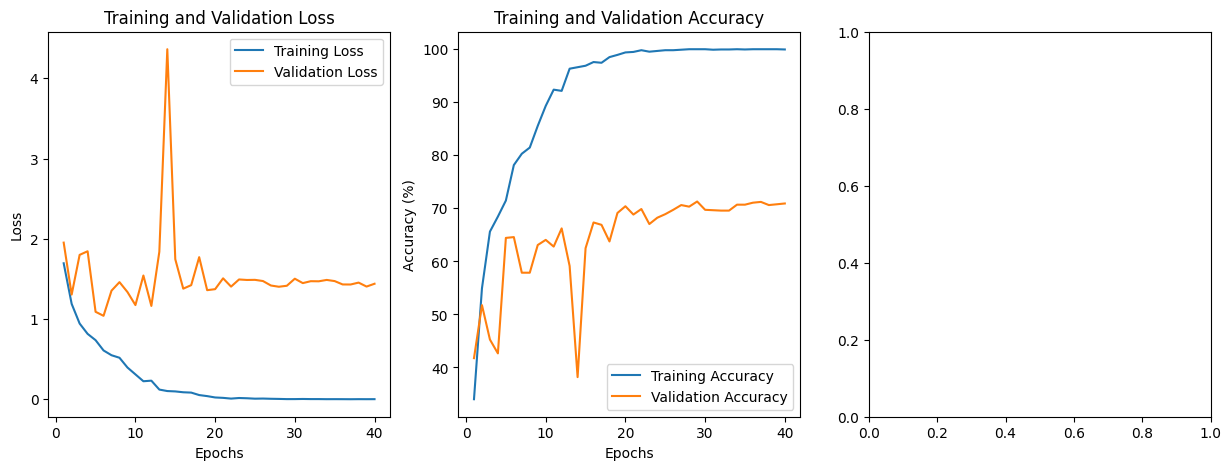

In [18]:
epochs = range(1, len(total_loss_train_plot) + 1)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.plot(epochs, total_loss_train_plot, label="Training Loss")
plt.plot(epochs, total_loss_validation_plot, label="Validation Loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()


plt.subplot(1, 3, 2)
plt.plot(epochs, total_acc_train_plot, label="Training Accuracy")
plt.plot(epochs, total_acc_validation_plot, label="Validation Accuracy")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy (%)")
plt.legend()


plt.subplot(1, 3, 3)
plt.plot(epochs, total_f1_validation_plot, label="Validation F1 Score")
plt.title("Validation F1 Score")
plt.xlabel("Epochs")
plt.ylabel("Macro F1")
plt.legend()


plt.tight_layout()
plt.show()